# COS40007 – Portfolio Assessment 3c: LSTM for Classification
**Dataset:** Seoul Bike Sharing Demand · **Target:** `demand_class` (Low / Medium / High), same as Portfolio 2

In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

I0000 00:00:1793330412.119440     314 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793330412.171113     314 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793330413.760897     314 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


# Part A: Traditional Machine Learning Models
## A.1 Load and analyse the dataset

In [2]:
df = pd.read_csv("SeoulBikeData.csv", encoding="latin-1")
df.columns = ["date", "rented_bike_count", "hour", "temperature", "humidity", "wind_speed", "visibility",
              "dew_point_temperature", "solar_radiation", "rainfall", "snowfall", "seasons", "holiday",
              "functioning_day"]
df["date"] = pd.to_datetime(df["date"], format="%d/%m/%Y")

# Same cleaning as Portfolio 1: remove closed hours and humidity = 0 sensor errors
df = df[(df["functioning_day"] == "Yes") & (df["humidity"] != 0)].drop(columns="functioning_day")
df = df.sort_values(["date", "hour"]).reset_index(drop=True)

# Same target as Portfolio 1/2: 3 balanced classes -> classification problem
class_names = ["Low", "Medium", "High"]
df["demand_class"] = pd.qcut(df["rented_bike_count"], q=3, labels=[0, 1, 2]).astype(int)

print("Shape:", df.shape)
df["demand_class"].value_counts().sort_index().rename(index=dict(enumerate(class_names)))

Shape: (8448, 14)


demand_class
Low       2816
Medium    2816
High      2816
Name: count, dtype: int64

In [3]:
# Engineered features from Portfolio 2
df["temp_x_hour"] = df["temperature"] * df["hour"]
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["is_weekend"] = (df["date"].dt.dayofweek >= 5).astype(int)
df["rush_workday"] = (df["hour"].isin([7, 8, 9, 17, 18, 19])
                      & (df["is_weekend"] == 0)
                      & (df["holiday"] == "No Holiday")).astype(int)
df["is_raining"] = (df["rainfall"] > 0).astype(int)
df["daily_rainfall"] = df.groupby("date")["rainfall"].transform("sum")

# Encode categorical features
df["holiday"] = (df["holiday"] == "Holiday").astype(int)
df = pd.concat([df, pd.get_dummies(df["seasons"], prefix="season", dtype=int)], axis=1)

feature_cols = ["hour", "temperature", "humidity", "wind_speed", "visibility", "dew_point_temperature",
                "solar_radiation", "rainfall", "snowfall", "holiday",
                "season_Autumn", "season_Spring", "season_Summer", "season_Winter",
                "temp_x_hour", "hour_sin", "hour_cos", "is_weekend", "rush_workday", "is_raining", "daily_rainfall"]
print("Number of features:", len(feature_cols))

Number of features: 21


## A.2 Preprocess the data

In [4]:
X = df[feature_cols]
y = df["demand_class"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

# Fit the scaler on the training set only, then apply it to both sets
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train:", X_train_s.shape)
print("Test :", X_test_s.shape)

Train: (5913, 21)
Test : (2535, 21)


## A.3 Train the models

In [5]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "MLP": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, early_stopping=True, random_state=RANDOM_STATE),
    "SVM (Portfolio 2, tuned)": SVC(kernel="rbf", C=100, gamma="scale"),
}

# Shuffle the folds because the data is sorted by time
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ml_results = {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    cv_scores = cross_val_score(make_pipeline(StandardScaler(), model), X, y, cv=cv)
    ml_results[name] = {
        "Accuracy (%)": accuracy_score(y_test, pred) * 100,
        "F1 weighted (%)": f1_score(y_test, pred, average="weighted") * 100,
        "5-fold CV (%)": cv_scores.mean() * 100,
    }
    print(f"{name} done")

Random Forest done


MLP done


SVM (Portfolio 2, tuned) done


## A.4 Evaluate and compare

In [6]:
ml_table = pd.DataFrame(ml_results).T.round(2)
ml_table

,Accuracy (%),F1 weighted (%),5-fold CV (%)
Random Forest,88.88,88.85,88.55
MLP,86.67,86.70,86.83
"SVM (Portfolio 2, tuned)",88.21,88.22,87.14


**Best model: Random Forest** (88.88% accuracy, 88.85% weighted F1, 88.55% CV). It averages 200 trees, which captures non-linear weather × time interactions without heavy tuning and reduces the overfitting of a single Decision Tree (83.39% in Portfolio 2). The MLP is ~2 points lower: with ~6,000 samples and default settings it is harder to optimise than tree ensembles on tabular data.

## A.5 Visualise results

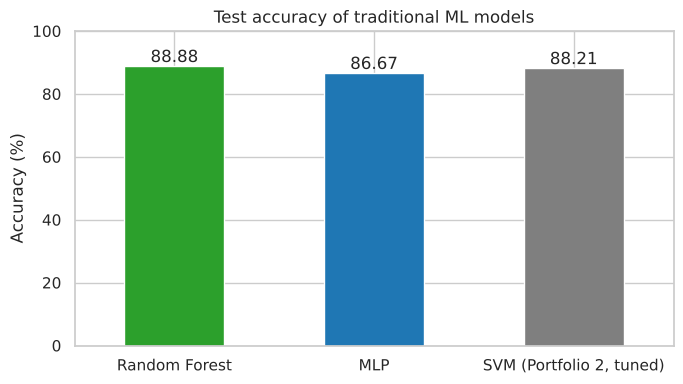

In [7]:
ax = ml_table["Accuracy (%)"].plot(kind="bar", figsize=(7, 4), rot=0, ylim=(0, 100), color=["tab:green", "tab:blue", "tab:grey"])
ax.bar_label(ax.containers[0], fmt="%.2f")
ax.set_title("Test accuracy of traditional ML models")
ax.set_ylabel("Accuracy (%)")
plt.tight_layout()
plt.savefig("partA_accuracy.png", dpi=150)
plt.show()

# Part B: Deep Learning – LSTM for Classification
## B.1 Prepare sequential data

In [8]:
# MinMaxScaler scales every feature to [0, 1]
features_scaled = MinMaxScaler().fit_transform(df[feature_cols])
labels = df["demand_class"].to_numpy()
timestamps = df["date"] + pd.to_timedelta(df["hour"], unit="h")

def make_sequences(seq_len):
    """Each sample = seq_len consecutive hours; label = demand class of the last hour."""
    X_seq, y_seq = [], []
    for end in range(seq_len - 1, len(df)):
        start = end - seq_len + 1
        # Keep only windows without gaps (removed hours in Portfolio 1 break the sequence)
        if timestamps[end] - timestamps[start] == pd.Timedelta(hours=seq_len - 1):
            X_seq.append(features_scaled[start:end + 1])
            y_seq.append(labels[end])
    return np.array(X_seq), np.array(y_seq)

SEQ_LEN = 24
X_seq, y_seq = make_sequences(SEQ_LEN)
Xs_train, Xs_test, ys_train, ys_test = train_test_split(X_seq, y_seq, test_size=0.3,
                                                        random_state=RANDOM_STATE, stratify=y_seq)

print("All sequences (samples, timesteps, features):", X_seq.shape)
print("Train:", Xs_train.shape, "| Test:", Xs_test.shape)

All sequences (samples, timesteps, features): (8040, 24, 21)
Train: (5628, 24, 21) | Test: (2412, 24, 21)


**Sequence length = 24 hours:** demand follows a daily cycle (morning and evening peaks, Portfolio 1 EDA), so one full day of history covers a whole cycle. Windows that cross a gap (hours removed in Portfolio 1) are dropped, so every sample contains 24 consecutive hours. Final shape: **(8,040 samples, 24 timesteps, 21 features)**.

## B.2 Build the LSTM architecture

In [9]:
def build_lstm(seq_len, n_features, n_classes=3):
    model = Sequential([
        Input(shape=(seq_len, n_features)),
        LSTM(64, return_sequences=True),
        Dropout(0.2),
        LSTM(32, return_sequences=False),
        Dropout(0.2),
        Dense(16, activation="relu"),
        Dense(n_classes, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

build_lstm(SEQ_LEN, X_seq.shape[2]).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        22,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,011 (136.76 KB)

 Trainable params: 35,011 (136.76 KB)

 Non-trainable params: 0 (0.00 B)

## B.3 Train the model

In [10]:
def train_lstm(X_tr, y_tr, seq_len, batch_size, epochs=50):
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    model = build_lstm(seq_len, X_tr.shape[2])
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5),
    ]
    history = model.fit(X_tr, y_tr, validation_split=0.2, epochs=epochs, batch_size=batch_size,
                        callbacks=callbacks, verbose=0)
    return model, history

# Start with 10 epochs to check that the model learns
_, quick_history = train_lstm(Xs_train, ys_train, SEQ_LEN, batch_size=32, epochs=10)
print("After 10 epochs -> val accuracy: %.2f%%" % (quick_history.history["val_accuracy"][-1] * 100))

After 10 epochs -> val accuracy: 82.95%


In [11]:
# Compare batch sizes with up to 50 epochs
batch_runs = {}
batch_summary = {}
for batch_size in [16, 32, 64]:
    model, history = train_lstm(Xs_train, ys_train, SEQ_LEN, batch_size)
    batch_runs[batch_size] = (model, history)
    batch_summary[batch_size] = {
        "Epochs run": len(history.history["loss"]),
        "Best val loss": min(history.history["val_loss"]),
        "Best val accuracy (%)": max(history.history["val_accuracy"]) * 100,
    }

batch_table = pd.DataFrame(batch_summary).T.round(3)
batch_table.index.name = "Batch size"
best_batch = int(batch_table["Best val loss"].idxmin())
print("Best batch size:", best_batch)
batch_table

Best batch size: 16


,Epochs run,Best val loss,Best val accuracy (%)
Batch size,,,
16,34.0,0.296,88.366
32,35.0,0.312,87.300
64,37.0,0.310,87.300


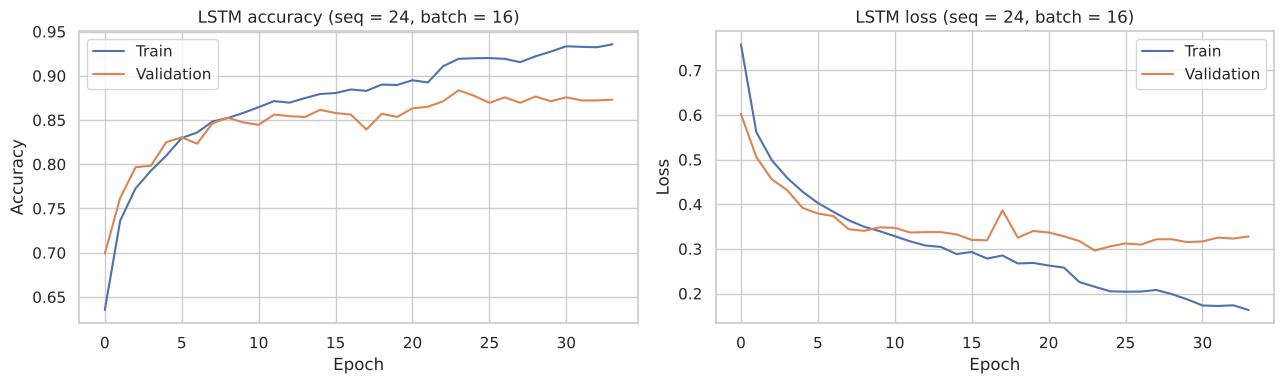

In [12]:
lstm_1, history_1 = batch_runs[best_batch]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_1.history["accuracy"], label="Train")
axes[0].plot(history_1.history["val_accuracy"], label="Validation")
axes[0].set_title(f"LSTM accuracy (seq = {SEQ_LEN}, batch = {best_batch})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[1].plot(history_1.history["loss"], label="Train")
axes[1].plot(history_1.history["val_loss"], label="Validation")
axes[1].set_title(f"LSTM loss (seq = {SEQ_LEN}, batch = {best_batch})")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
plt.tight_layout()
plt.savefig("partB_training_curves.png", dpi=150)
plt.show()

**Training:** after 10 epochs the validation accuracy was already 82.95%, so training was extended to 50 epochs with early stopping. Batch size 16 gave the lowest validation loss (0.296) and was selected. Both training and validation loss decrease for the first ~23 epochs; afterwards the training loss keeps falling while the validation loss flattens, so early stopping restored the best weights and the learning rate was halved when the validation loss plateaued.

## B.4 Evaluate the LSTM model

Test accuracy: 88.23% | Test loss: 0.2846 | F1 weighted: 88.25%
              precision    recall  f1-score   support

         Low      0.939     0.882     0.910       816
      Medium      0.822     0.837     0.830       812
        High      0.890     0.929     0.909       784

    accuracy                          0.882      2412
   macro avg      0.884     0.883     0.883      2412
weighted avg      0.884     0.882     0.883      2412



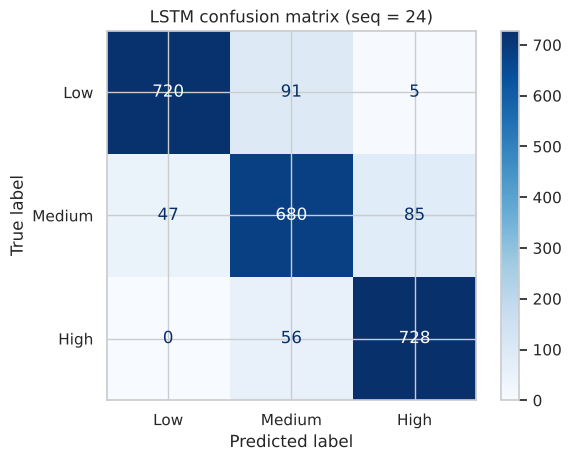

In [13]:
test_loss_1, test_acc_1 = lstm_1.evaluate(Xs_test, ys_test, verbose=0)
pred_1 = lstm_1.predict(Xs_test, verbose=0).argmax(axis=1)
f1_1 = f1_score(ys_test, pred_1, average="weighted") * 100

print(f"Test accuracy: {test_acc_1 * 100:.2f}% | Test loss: {test_loss_1:.4f} | F1 weighted: {f1_1:.2f}%")
print(classification_report(ys_test, pred_1, target_names=class_names, digits=3))

ConfusionMatrixDisplay(confusion_matrix(ys_test, pred_1), display_labels=class_names).plot(cmap="Blues")
plt.title(f"LSTM confusion matrix (seq = {SEQ_LEN})")
plt.savefig("partB_confusion_matrix.png", dpi=150)
plt.show()

In [14]:
# Second LSTM: longer sequence (48 hours = 2 days), same architecture and batch size
SEQ_LEN_2 = 48
X_seq2, y_seq2 = make_sequences(SEQ_LEN_2)
X2_train, X2_test, y2_train, y2_test = train_test_split(X_seq2, y_seq2, test_size=0.3,
                                                        random_state=RANDOM_STATE, stratify=y_seq2)
lstm_2, history_2 = train_lstm(X2_train, y2_train, SEQ_LEN_2, best_batch)

test_loss_2, test_acc_2 = lstm_2.evaluate(X2_test, y2_test, verbose=0)
pred_2 = lstm_2.predict(X2_test, verbose=0).argmax(axis=1)
f1_2 = f1_score(y2_test, pred_2, average="weighted") * 100
print("Sequences:", X_seq2.shape)
print(f"Test accuracy: {test_acc_2 * 100:.2f}% | Test loss: {test_loss_2:.4f} | F1 weighted: {f1_2:.2f}%")

Sequences: (7753, 48, 21)
Test accuracy: 87.96% | Test loss: 0.2945 | F1 weighted: 88.05%


In [15]:
# LSTM vs best traditional model from Part A
best_ml = ml_table["Accuracy (%)"].idxmax()
comparison = pd.DataFrame({
    "Accuracy (%)": [ml_table.loc[best_ml, "Accuracy (%)"], test_acc_1 * 100, test_acc_2 * 100],
    "F1 weighted (%)": [ml_table.loc[best_ml, "F1 weighted (%)"], f1_1, f1_2],
}, index=[best_ml, f"LSTM (seq = {SEQ_LEN})", f"LSTM (seq = {SEQ_LEN_2})"]).round(2)
comparison

,Accuracy (%),F1 weighted (%)
Random Forest,88.88,88.85
LSTM (seq = 24),88.23,88.25
LSTM (seq = 48),87.96,88.05


**LSTM vs traditional ML:** the LSTM (seq = 24) reaches 88.23% accuracy, 0.65 points **below** the Random Forest (88.88%), so it did not outperform the best traditional model. Most of the predictive information is in the current hour (hour, temperature, engineered features), which the tabular models already use; the extra 23 hours of history add little. The 48-hour window is slightly worse (87.96%) because it has fewer samples (7,753) and more noise. Medium is the hardest class (F1 0.83) because it lies between the other two.

## B.5 Save the model

In [16]:
lstm_1.save("lstm_seq24.h5")
lstm_2.save("lstm_seq48.h5")

with open("lstm_seq24_history.pkl", "wb") as f:
    pickle.dump(history_1.history, f)
with open("lstm_seq48_history.pkl", "wb") as f:
    pickle.dump(history_2.history, f)
print("Saved models (.h5) and training histories (.pkl)")

Saved models (.h5) and training histories (.pkl)
